# A. EDA complémentaire

**Contributeurs :** Cécile · **Date :** 27/10/2026

Analyses réalisées après le premier rapport. Équipements : nouvelle source, la BPE en évolution de l'Insee (nombre d'équipements par bassin de vie en 2015, 2020 et 2025), à la place de la table de présence par commune.

## 0. Chargement

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display
import re

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 100)

# config.py se trouve à la racine du projet
racine = Path.cwd()
while not (racine / "config.py").exists() and racine != racine.parent:
    racine = racine.parent
sys.path.insert(0, str(racine))
from config import DATA_RAW, DATA_OUT

pd.set_option("display.max_columns", None)

fichier = DATA_OUT / "fe_cible_toutes_sources_sbv_encodee.parquet"
df = pd.read_parquet(fichier)

if "annee_sbv_typebien" not in df.columns:      # la clé peut être dans l'index
    df = df.reset_index()

TARGET = "prix_m2_med"

In [2]:
# La clé a la forme  <annee>_<sbv>_<typebien>  ; sbv peut contenir un suffixe _N (ex. 06029_1)
key = df["annee_sbv_typebien"]
df["sbv"] = key.str.split("_", n=1).str[1].str.rsplit("_", n=1).str[0]
df["typebien"] = key.str.rsplit("_", n=1).str[1]
df["dept"] = df["sbv"].str[:2]

**Constat :** la clé annee_sbv_typebien encode trois informations, et certaines zones ont un suffixe (06029_1, 241 zones).

**Interprétation :** sbv n’est pas un code commune pur, c’est un découpage de zone. Une commune peut donc être subdivisée.

**Conséquence :** il faut parser avec split(n=1) puis rsplit(n=1), pas un simple split("_"). Pour une jointure avec une source externe par code INSEE, il faudra gérer ces suffixes.

## 1. Audit rapide

**Contributeurs :** Gabrielle · **Date :** 30/10/2026

In [3]:
# Structure

print("shape :", df.shape)
print(df.dtypes.value_counts().to_string())
print(df.head(3).T.head(15).to_string())

shape : (43604, 61)
float64    46
int64      11
object      3
str         1
                                              0                       1                  2
annee_sbv_typebien            2014_01004_maison  2014_01004_appartement  2015_01004_maison
annee                                      2014                    2014               2015
maison                                        1                       0                  1
appartement                                   0                       1                  0
nb_biens                                    368                      59                379
nb_ventes_n1                                NaN                     NaN              368.0
prix_m2_med                              1691.0                  1836.0             1667.0
nb_vols_vehicules                           NaN                     NaN                NaN
nb_vols_violents                            NaN                     NaN                NaN
nb_vols_sans_v

**Constat :** 43 604 × 58, presque tout en float, une seule colonne texte (la clé).

**Interprétation :** le fichier est déjà un jeu de features numériques, prêt à modéliser.

**Conséquence :** la clé n’est pas une feature, elle sert d’identifiant. sbv, typebien et dept sont dérivés dans le script, pas dans le fichier d’origine.

In [4]:
#clé et panel

print("doublons clé        :", key.duplicated().sum())
print("zones (sbv)         :", df["sbv"].nunique(), "| départements :", df["dept"].nunique())
print("années              :", sorted(df["annee"].unique()))
print("lignes par année    :", df.groupby("annee").size().to_dict())
print("lignes par typebien :", df["typebien"].value_counts().to_dict())
obs = df.groupby(["sbv", "typebien"]).size()
print("obs par zone x type :", obs.describe()[["min", "50%", "max"]].to_dict())
print("annee == annee de la clé :", (key.str[:4].astype(int) == df["annee"]).all())

doublons clé        : 0
zones (sbv)         : 1817 | départements : 93
années              : [np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]
lignes par année    : {2014: 3632, 2015: 3634, 2016: 3634, 2017: 3634, 2018: 3634, 2019: 3634, 2020: 3634, 2021: 3634, 2022: 3632, 2023: 3634, 2024: 3634, 2025: 3634}
lignes par typebien : {'maison': 21802, 'appartement': 21802}
obs par zone x type : {'min': 11.0, '50%': 12.0, 'max': 12.0}
annee == annee de la clé : True


**Constat :** 0 doublon, 1 817 zones × 2 types × 12 ans, 11 ou 12 observations par zone × type.

**Interprétation :** c’est un panel équilibré, avec les mêmes zones suivies sur toute la période.

**Conséquence :** un split aléatoire est à proscrire, car la même zone se retrouverait en train et en test. Il faut un split temporel, par exemple test sur 2024-2025, ou groupé par zone. On peut aussi exploiter la dimension panel avec des lags et des effets zone.

In [5]:
# valeurs manquantes
na = (df.isna().mean() * 100).round(1).sort_values(ascending=False)
print(na[na > 0].to_string())

taux3_cambriolages                 41.7
taux3_vols_violents                41.7
taux3_vols_sans_violence           41.7
taux3_destructions                 41.7
taux3_vols_vehicules               41.7
taux3_violences_intrafamiliales    41.7
taux3_violences_sexuelles          41.7
taux3_stupefiants                  41.7
nb_stupefiants                     25.0
nb_vols_sans_violence              25.0
insee_pop                          25.0
nb_violences_intrafamiliales       25.0
nb_destructions                    25.0
taux1_vols_violents                25.0
taux1_vols_vehicules               25.0
part_indicateurs_estimes           25.0
insee_log                          25.0
taux1_cambriolages                 25.0
taux1_vols_sans_violence           25.0
taux1_destructions                 25.0
nb_violences_sexuelles             25.0
taux1_stupefiants                  25.0
nb_cambriolages                    25.0
annee_faits                        25.0
taux1_violences_sexuelles          25.0


**Constat :** la délinquance, insee_* et annee_faits sont à 25 % de nulls, les taux3_* à 41,7 %, la cible à 6 %.

**Interprétation :** la majorité des nulls sont de l’indisponibilité historique, pas du hasard.

**Conséquence :** une imputation par la moyenne serait trompeuse. Choisis entre restreindre l’entraînement aux années complètes (2019+ pour les taux3_*), ou garder toutes les années avec des modèles tolérant les NaN (LightGBM). Dans ce cas, les taux3_* sont de toute façon quasi redondants avec les taux1_*.

In [6]:
#Nulls par année (% ) — colonnes représentatives"
cols_na = [TARGET, "nb_ventes_n1", "nb_vols_vehicules", "taux1_cambriolages",
           "taux3_cambriolages", "insee_pop"]
print(df.groupby("annee")[cols_na].apply(lambda g: g.isna().mean() * 100).round(0).T.to_string())

annee                2014   2015   2016   2017   2018  2019  2020  2021  2022  2023  2024  2025
prix_m2_med           8.0    7.0    7.0    7.0    7.0   6.0   6.0   5.0   5.0   5.0   6.0   5.0
nb_ventes_n1        100.0    0.0    0.0    0.0    0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0
nb_vols_vehicules   100.0  100.0  100.0    0.0    0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0
taux1_cambriolages  100.0  100.0  100.0    0.0    0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0
taux3_cambriolages  100.0  100.0  100.0  100.0  100.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0
insee_pop           100.0  100.0  100.0    0.0    0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0


**Constat :** les nulls sont en blocs par année : délinquance absente 2014-2016, taux3_* absents 2014-2018, nb_ventes_n1 absent en 2014.

**Interprétation :** c’est un effet de fenêtre temporelle de calcul (moyenne glissante sur 3 ans, décalage N-1), pas un défaut de qualité de la donnée.

**Conséquence :** les années récentes sont plus riches en features que les anciennes. Le modèle voit donc des distributions différentes selon l’année, ce qui pèse sur la comparabilité train/test.

In [7]:
# Cible : nulls vs nb_biens"
print("prix nul & nb_biens > 0  :", (df[TARGET].isna() & (df["nb_biens"] > 0)).sum())
print("prix nul & nb_biens == 0 :", (df[TARGET].isna() & (df["nb_biens"] == 0)).sum())
print("part des lignes avec nb_biens < 5 :", round((df["nb_biens"] < 5).mean(), 3))

prix nul & nb_biens > 0  : 0
prix nul & nb_biens == 0 : 2610
part des lignes avec nb_biens < 5 : 0.155


**Constat :** tous les nulls de prix_m2_med (2 610) correspondent à nb_biens == 0, et 15,5 % des lignes ont moins de 5 ventes.

**Interprétation :** le prix est absent parce qu’il n’y a pas de vente, ce n’est pas une donnée perdue. Avec peu de ventes, la médiane est très bruitée.

**Conséquence :** exclus les lignes sans prix de l’entraînement. Envisage un seuil minimal de ventes, ou une pondération par nb_biens, pour éviter d’apprendre sur du bruit. Un modèle ne pourra jamais prédire un prix là où il n’y a pas de marché.

In [8]:
# distribution valeurs numériques
num_cols = [c for c in df.select_dtypes("number").columns if c not in ("maison", "appartement")]
desc = df[num_cols].describe(percentiles=[0.01, 0.5, 0.99]).T
print(desc[["count", "mean", "std", "min", "1%", "50%", "99%", "max"]].round(2).to_string())

                                   count      mean        std       min        1%       50%        99%         max
annee                            43604.0   2019.50       3.45   2014.00   2014.00   2019.50    2025.00     2025.00
nb_biens                         43604.0    221.43    1185.06      0.00      0.00     88.00    1959.97    70042.00
nb_ventes_n1                     39972.0    221.71    1193.65      0.00      0.00     88.00    1961.29    70042.00
prix_m2_med                      40994.0   2022.13    1562.37     53.00    455.00   1673.00    8613.07    42581.00
nb_vols_vehicules                32704.0    206.05    1585.00      0.00      3.90     48.85    2149.88    71558.56
nb_vols_violents                 32704.0     40.56     473.84      0.00      0.00      3.02     757.94    27057.55
nb_vols_sans_violence            32704.0    343.44    2420.62      0.00      7.76     64.41    6218.70    97663.62
nb_cambriolages                  32704.0    116.28     737.55      0.00      4.4

**Constat :** les volumes (nb_*, insee_pop, nb_equip_*) ont des queues très lourdes (médiane de 88 pour nb_biens, max de 70 042). Les taux* sont plus calmes, sauf vols_sans_violence (max 675) et stupefiants (max 176).

**Interprétation :** les maxima viennent des grandes villes comme Paris, pas d’erreurs de saisie. Les pics des taux* correspondent plutôt à des zones à faible population, où un petit nombre de faits donne un taux élevé.

**Conséquence :** ne supprime pas ces outliers, ils sont réels. Utilise des transformations log pour les volumes, et regarde la robustesse des taux* dans les zones peu peuplées.

In [9]:
# distribution asymétrique des variables numériques
skew = df[num_cols].skew().sort_values(ascending=False)
print(skew[skew > 3].round(1).to_string())
print(f"\n{TARGET}: skew brut = {df[TARGET].skew():.2f} | skew log = {np.log(df[TARGET]).skew():.2f}")

nb_equip_transports             41.8
nb_violences_intrafamiliales    40.8
nb_vols_violents                40.7
nb_ventes_n1                    39.5
nb_biens                        39.4
nb_violences_sexuelles          38.9
nb_stupefiants                  38.7
insee_pop                       37.9
nb_menages_fiscaux              36.9
nb_equip_services               36.1
insee_log                       36.0
nb_destructions                 35.9
nb_equip_sports                 35.1
nb_cambriolages                 34.7
nb_equip_commerces              33.4
nb_vols_vehicules               32.8
nb_equip_sante                  31.1
nb_equip_tourisme               31.0
nb_vols_sans_violence           30.9
taux1_vols_sans_violence        19.2
taux3_vols_sans_violence        18.7
taux1_stupefiants               17.6
taux3_stupefiants               16.0
taux1_vols_violents             14.1
taux3_vols_violents             13.8
taux1_vols_vehicules             6.0
prix_m2_med                      6.0
t

**Constat :** prix_m2_med a un skew de 5,98, qui tombe à 0,23 après log.

**Interprétation :** la distribution est quasi log-normale, ce qui est typique des prix immobiliers.

**Conséquence :** modélise log(prix_m2_med). Tu travailles alors en erreur relative, pas en euros, et Paris ne domine plus la fonction de perte. Applique le même traitement aux variables de volume très asymétriques.

# B. Relations entre les variables

### B1. La cible dans le temps

In [10]:
print(df.pivot_table(index="typebien", columns="annee", values=TARGET, aggfunc="median").round(0).to_string())

annee          2014    2015    2016    2017    2018    2019    2020    2021    2022    2023    2024    2025
typebien                                                                                                   
appartement  1534.0  1504.0  1488.0  1500.0  1504.0  1515.0  1571.0  1684.0  1855.0  1891.0  1905.0  1932.0
maison       1516.0  1500.0  1514.0  1543.0  1574.0  1596.0  1686.0  1813.0  1983.0  1990.0  1937.0  1960.0


**Constat :** prix plats de 2014 à 2019 (~1 500 €/m²), puis ~+25 % entre 2020 et 2022, avec des maisons au-dessus des appartements depuis 2018.

**Interprétation :** il y a une rupture de marché post-2020 (effet post-Covid, taux bas), et le type de bien change le comportement du prix.

**Conséquence :** annee sera un prédicteur dominant, mais risqué. Un modèle à base d’arbres ne extrapole pas hors de la plage de prix vue à l’entraînement. Pour une prévision hors période, mieux vaut prédire une variation (log du ratio au prix précédent de la zone) ou déflater par un indice national. Garde typebien en interaction ou entraîne deux modèles.

In [11]:
# top 10 départements
print(df.groupby("dept")[TARGET].median().sort_values(ascending=False).head(10).round(0).to_string())

dept
75    10526.0
06     3718.0
74     3674.0
2A     3550.0
13     3220.0
83     3114.0
95     2891.0
78     2870.0
91     2814.0
2B     2772.0


**Constat :** Paris (75) à ~10 500 €/m², loin devant le suivant (06 à ~3 700).

**Interprétation :** la distribution géographique est très inégale, avec des zones chères (Paris, Côte d’Azur, Haute-Savoie, Corse) et un gros du territoire entre 1 000 et 2 500 €.

**Conséquence :** le département ou la localisation sera une information majeure. Fais attention à un dept encodé en entier (il n’est pas ordinal) et à la cardinalité (93 valeurs) : préfère un target encoding sur le passé, ou des coordonnées géographiques.

### B2. Corrélations

In [12]:
# corrélation de spearman avec la cible, le top 15 uniquement
num = df[num_cols]
corr_t = num.corr(method="spearman")[TARGET].drop(TARGET).dropna()
print(corr_t.reindex(corr_t.abs().sort_values(ascending=False).index).head(15).round(2).to_string())

taux_vacance                 -0.67
part_avant1946               -0.63
anciennete_moyenne           -0.63
niveau_vie_median             0.62
part_2006_2019                0.50
part_logements_taux_impute   -0.46
nb_equip_transports           0.44
part_apparts                  0.43
taux_vacance_complete        -0.41
part_suroccupes               0.37
part_moins40m2                0.37
taux3_vols_vehicules          0.35
taux3_vols_violents           0.35
taux1_vols_vehicules          0.34
nb_vols_violents              0.34


**Constat :** les plus fortes sont taux_vacance (−0,67), part_avant1946 et anciennete_moyenne (−0,63), niveau_vie_median (+0,62). La délinquance est à ~+0,35.

**Interprétation :** les prix suivent le dynamisme de la zone (peu de vacance, parc récent, revenus élevés). La corrélation positive avec la délinquance reflète un effet d’urbanité (grandes villes denses = plus chères et plus de faits enregistrés), pas un effet causal.

**Conséquence :** ne lis pas la délinquance comme un facteur qui fait monter les prix. Contrôle la densité, et utilise une importance de variables par permutation ou SHAP plutôt que les corrélations brutes.

In [13]:
# les paires redondantes cad corrélation > 0.95
cm = num.drop(columns=TARGET).corr(method="spearman").abs()
upper = cm.where(np.triu(np.ones(cm.shape, dtype=bool), k=1))
pairs = upper.stack()
print(pairs[pairs > 0.95].sort_values(ascending=False).round(3).to_string())

annee              annee_faits           1.000
                   annee_ventes          1.000
annee_faits        annee_ventes          1.000
insee_log          log_nb_logements      0.999
insee_pop          nb_menages_fiscaux    0.995
nb_biens           nb_ventes_n1          0.989
nb_equip_services  log_nb_logements      0.952


**Constat :** annee / annee_faits / annee_ventes (1,0), insee_log / log_nb_logements (0,999), insee_pop / nb_menages_fiscaux (0,995), nb_biens / nb_ventes_n1 (0,989).

**Interprétation :** ce sont les mêmes informations sous différents noms, ou des décalages fixes.

**Conséquence :** retire les doublons. Pas d’impact sur la performance d’un arbre, mais pour un modèle linéaire ou des importances lisibles, c’est utile.

In [14]:
# comparaison de insee_pop et insee_log avec d'autres variables avec lesquelles elles sont corrélées
print("insee_pop vs nb_menages_fiscaux  :",
      round(df[["insee_pop", "nb_menages_fiscaux"]].corr(method="spearman").iloc[0, 1], 4))
print("insee_log vs log_nb_logements    :",
      round(df[["insee_log", "log_nb_logements"]].corr(method="spearman").iloc[0, 1], 4))
print("nulls insee_pop / nb_menages_fiscaux :",
      f"{df['insee_pop'].isna().mean():.1%} / {df['nb_menages_fiscaux'].isna().mean():.1%}")
print("nulls insee_log / log_nb_logements   :",
      f"{df['insee_log'].isna().mean():.1%} / {df['log_nb_logements'].isna().mean():.1%}")

insee_pop vs nb_menages_fiscaux  : 0.9945
insee_log vs log_nb_logements    : 0.9994
nulls insee_pop / nb_menages_fiscaux : 25.0% / 0.0%
nulls insee_log / log_nb_logements   : 25.0% / 0.0%


**Constat :** insee_pop et insee_log ont 25 % de nulls, nb_menages_fiscaux et log_nb_logements aucun.

**Interprétation :** les équivalents font le même travail sans les trous.

**Conséquence :** supprime insee_pop et insee_log, et garde les deux autres. Tu gagnes 14 % de complétude sur ces variables.

### B2. graphes


Graphique enregistré : eda_apercu.png


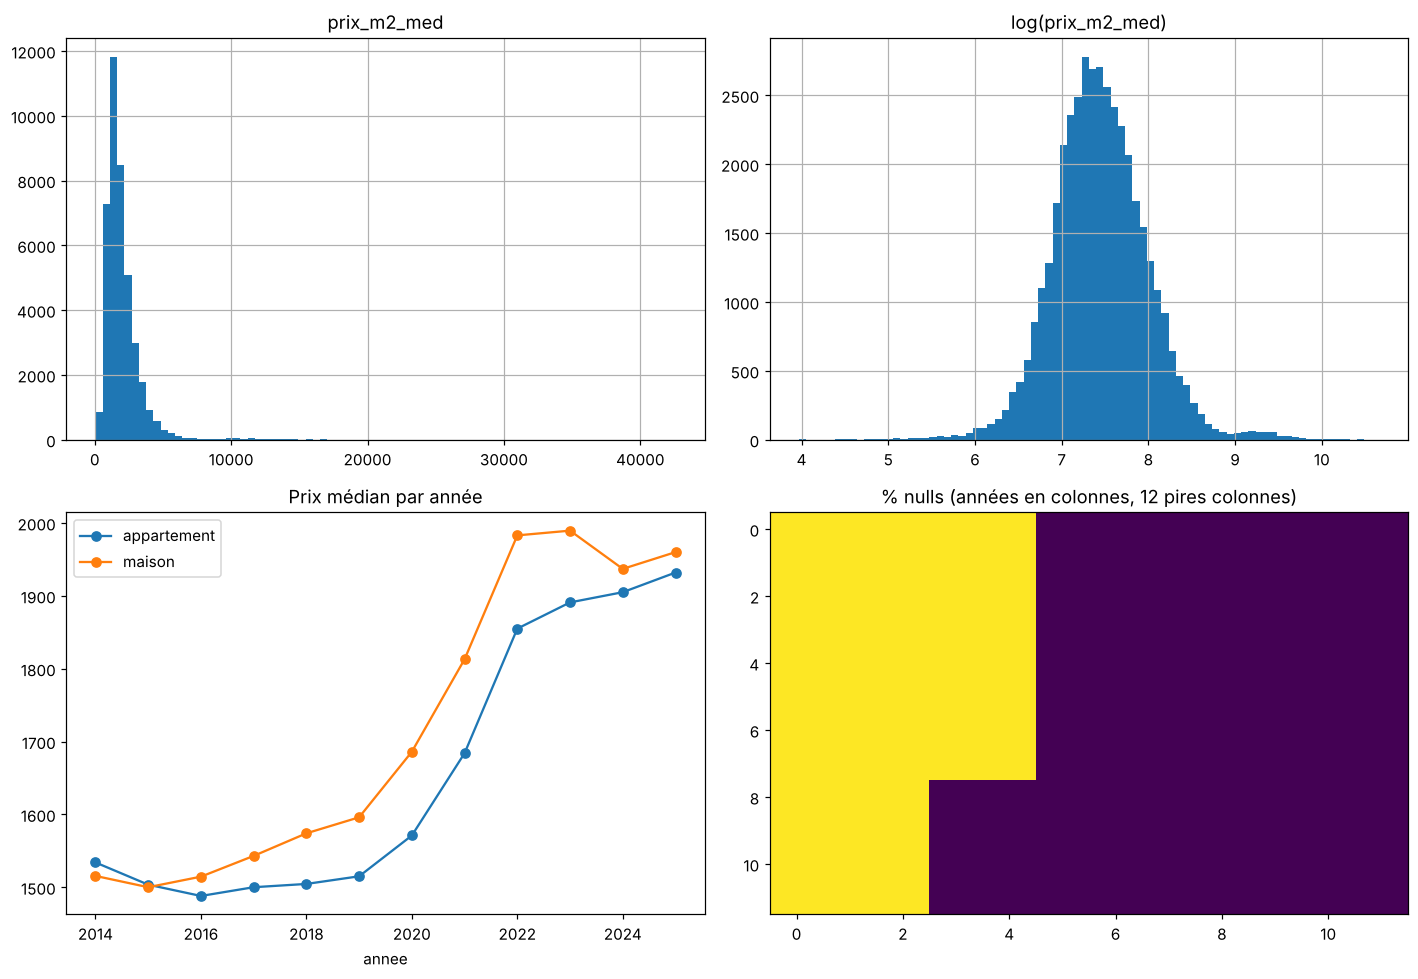

In [15]:
try:
    import matplotlib.pyplot as plt
 
    fig, ax = plt.subplots(2, 2, figsize=(13, 9))
    df[TARGET].hist(bins=80, ax=ax[0, 0]); ax[0, 0].set_title(f"{TARGET}")
    np.log(df[TARGET]).hist(bins=80, ax=ax[0, 1]); ax[0, 1].set_title(f"log({TARGET})")
    for t, g in df.groupby("typebien"):
        g.groupby("annee")[TARGET].median().plot(ax=ax[1, 0], marker="o", label=t)
    ax[1, 0].set_title("Prix médian par année"); ax[1, 0].legend()
    (df.isna().groupby(df["annee"]).mean() * 100).loc[:, na[na > 0].index[:12]].T.pipe(
        lambda m: ax[1, 1].imshow(m.values, aspect="auto", cmap="viridis"))
    ax[1, 1].set_title("% nulls (années en colonnes, 12 pires colonnes)")
    plt.tight_layout()
    plt.savefig("eda_apercu.png", dpi=120)
    print("\nGraphique enregistré : eda_apercu.png")
except ImportError:
    print("\n(matplotlib absent : graphiques ignorés)")

**Constat :** distribution brute vs log, tendance par type, carte des nulls par année.

**Interprétation :** c’est un contrôle visuel qui confirme les points 6, 8 et 9.

**Conséquence :** à regarder avant de figer les transformations.

# C. Synthèse

Périmètre : 43 604 lignes × 58 colonnes, panel équilibré de 1 817 sous-bassins × 2 types de bien × 12 ans (2014-2025). La cible retenue est prix_m2_med.

| #   | Constat majeur                                                         | Preuve                                                                                                                                                                    | Conséquence projet                                                                             | Action                                                                                                 |
| --- | ---------------------------------------------------------------------- | ------------------------------------------------------------------------------------------------------------------------------------------------------------------------- | ---------------------------------------------------------------------------------------------- | ------------------------------------------------------------------------------------------------------ |
| 1   | Panel équilibré et clé propre                                          | 0 doublon de clé ; 11 à 12 observations par sous-bassin × type                                                                                                            | Les observations d'une même zone sont liées dans le temps                                      | Split **temporel** (ex. test 2024-2025) ou groupé par zone, jamais aléatoire                           |
| 2   | La cible est log-normale                                               | Skew de 5,98 en brut contre 0,23 après `log` ; médiane 1 673 €, max 42 581 €                                                                                              | Paris et les zones chères dominent une perte en euros                                          | Modéliser `log(prix_m2_med)`                                                                           |
| 3   | 6 % de cible manquante, uniquement là où il n'y a pas de vente         | 2 610 lignes à `nb_biens == 0`, toutes avec prix nul, 0 prix nul avec `nb_biens > 0`                                                                                      | Le prix n'existe pas, il n'est pas imputable                                                   | Exclure ces lignes de l'entraînement                                                                   |
| 4   | Le seuil de 20 ventes tient au niveau sous-bassin, pas au niveau ligne | Min de 32 ventes par sous-bassin (tous types et années cumulés) ; 28,1 % des lignes ≤ 20 ventes                                                                           | Le bruit sur la cible reste fort dans les cellules à faible volume                             | Garder le seuil amont ; découper l'erreur par tranche de `nb_biens` à l'évaluation                     |
| 5   | Les nulls sont structurels et par blocs d'années                       | Délinquance et `insee_*` absents 2014-2016 (25 %) ; `taux3_*` absents 2014-2018 (41,7 %) ; `nb_ventes_n1` absent en 2014                                                  | Les années anciennes ont moins de features que les récentes                                    | Restreindre les années, ou utiliser un modèle tolérant les NaN (LightGBM), sans imputer par la moyenne |
| 6   | Rupture de marché après 2020                                           | Médiane ~1 500 €/m² en 2014-2019, puis ~1 950 € en 2022-2025 (+25 %)                                                                                                      | `annee` est un prédicteur fort mais risqué : un arbre n'extrapole pas hors de sa plage de prix | Tester la prédiction d'une variation par rapport au prix précédent de la zone, ou un déflateur         |
| 7   | Les prix sont portés par la dynamique locale, pas par la délinquance   | Spearman : `taux_vacance` −0,67, `part_avant1946` −0,63, `niveau_vie_median` +0,62 ; délinquance ~+0,35                                                                   | La corrélation délinquance-prix reflète l'urbanité, pas une causalité                          | Interpréter avec SHAP ou l'importance par permutation, pas par corrélations brutes                     |
| 8   | Redondances fortes entre variables                                     | `insee_log` / `log_nb_logements` 0,999 ; `insee_pop` / `nb_menages_fiscaux` 0,995 ; `nb_biens` / `nb_ventes_n1` 0,989 ; `annee_faits` et `annee_ventes` = `annee` décalée | Information dupliquée, avec 25 % de nulls sur `insee_*` contre 0 % sur leurs équivalents       | Supprimer `insee_pop`, `insee_log`, `annee_faits`, `annee_ventes`, et probablement `nb_ventes_n1`      |
| 9   | Queues très lourdes sur les volumes                                    | `nb_biens` : médiane 88, max 70 042 ; `insee_pop` max 8,5 M ; pics sur `taux*_vols_sans_violence` (675)                                                                   | Les valeurs extrêmes sont réelles (grandes villes, petites zones), pas des erreurs             | Ne pas supprimer les outliers ; passer les volumes en log                                              |

## Variables candidates pour la modélisation

| Variable                                                                                                                                                                                                   | Justification rapide                                                                                                                       |
| ---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- | ------------------------------------------------------------------------------------------------------------------------------------------ |
| `maison`, `appartement`                                                                                                                                                                                    | Déjà encodées ; le type de bien change le niveau de prix (maisons au-dessus depuis 2018)                                                   |
| `annee`                                                                                                                                                                                                    | Capte la dérive du marché, surtout après 2020 ; à surveiller pour l'extrapolation                                                          |
| `taux_vacance`                                                                                                                                                                                             | Meilleur signal univarié (ρ = −0,67), proxy d'attractivité de la zone                                                                      |
| `taux_vacance_complete`                                                                                                                                                                                    | ρ = −0,41, 24 nulls ; à garder seulement si elle apporte du signal en plus de `taux_vacance`                                               |
| `niveau_vie_median`                                                                                                                                                                                        | ρ = +0,62, 0 null ; capacité d'achat locale                                                                                                |
| `part_avant1946`                                                                                                                                                                                           | ρ = −0,63 ; âge du parc                                                                                                                    |
| `anciennete_moyenne`                                                                                                                                                                                       | ρ = −0,63 ; proche de `part_avant1946`, à tester si l'une des deux suffit                                                                  |
| `part_2006_2019`                                                                                                                                                                                           | ρ = +0,50 ; part de logements récents                                                                                                      |
| `part_apparts`                                                                                                                                                                                             | ρ = +0,43 ; caractère urbain du parc                                                                                                       |
| `part_moins40m2`, `part_suroccupes`                                                                                                                                                                        | ρ ≈ +0,37 ; densité et tension du parc                                                                                                     |
| `part_rsec`, `part_sans_voiture`, `part_parking`, `taille_menage`                                                                                                                                          | Structure du parc et des ménages, complètes (0 null) ; à garder si le modèle les valorise                                                  |
| `log_nb_logements`                                                                                                                                                                                         | Taille de la zone, déjà en log et sans null ; remplace `insee_log`                                                                         |
| `nb_menages_fiscaux`                                                                                                                                                                                       | Taille de la zone, sans null ; à passer en log ; remplace `insee_pop`                                                                      |
| `nb_biens`                                                                                                                                                                                                 | Volume du marché et indicateur de fiabilité du prix ; à passer en log, à vérifier qu'il est disponible au moment de prédire                |
| `nb_equip_transports`, `nb_equip_commerces`, `nb_equip_sante`, `nb_equip_sports`, `nb_equip_tourisme`                                                                                                      | Niveau d'équipement (ρ = +0,44 pour les transports) ; à passer en log                                                                      |
| `nb_equip_services`                                                                                                                                                                                        | ρ = 0,95 avec `log_nb_logements` ; à retirer ou à ramener au nombre de logements                                                           |
| `taux1_vols_vehicules`, `taux1_vols_violents`, `taux1_vols_sans_violence`, `taux1_cambriolages`, `taux1_destructions`, `taux1_stupefiants`, `taux1_violences_intrafamiliales`, `taux1_violences_sexuelles` | Déjà ramenés à la population ; disponibles dès 2017, avec des NaN avant ; à garder pour l'effet marginal                                   |
| `part_logements_taux_impute`, `part_indicateurs_estimes`                                                                                                                                                   | Indicateurs de qualité des données ; `part_logements_taux_impute` a ρ = −0,46, à vérifier si c'est un proxy rural plutôt qu'un vrai signal |

À exclure : insee_pop, insee_log, annee_faits, annee_ventes, nb_ventes_n1, les taux3_* (redondants avec les taux1_*, 41,7 % de nulls) et les nb_* de délinquance (proxys de taille de zone, alors que les taux1_* sont normalisés).

# D. Nature des variables : ce qui varie dans le temps, et ce qui ne varie pas

**Contributeurs :** Gabrielle · **Date :** 03/11/2026

Sections D, E et H : structure des variables et réduction de dimension (ACP). Dépendances : numpy, pandas, scipy, scikit-learn, matplotlib, seaborn.

In [16]:
# Outils pour les sections D à H (scikit-learn, scipy, numpy : pas d'autre dépendance)
import warnings
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold, KFold, cross_val_predict
warnings.filterwarnings("ignore", category=RuntimeWarning)

COUL = {"appartement": "#2a78d6", "maison": "#eb6834"}   # couleur fixe par type de bien, dans tous les graphes
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "figure.dpi": 110})

feats = [c for c in df.select_dtypes("number").columns if c not in (TARGET, "annee", "maison", "appartement")]

# 1) Les features sont-elles différentes entre la ligne maison et la ligne appartement d'une même zone × année ?
wa = df[df["typebien"] == "appartement"].set_index(["sbv", "annee"]).sort_index()
wm = df[df["typebien"] == "maison"].set_index(["sbv", "annee"]).sort_index().reindex(wa.index)
diff_type = [c for c in feats if not np.allclose(wa[c].fillna(-999), wm[c].fillna(-999))]

# 2) Varient-elles dans le temps pour une même zone ?
zm = df[df["typebien"] == "maison"]
varie = pd.Series({c: (zm.groupby("sbv")[c].nunique() > 1).mean() for c in feats})
statiques = sorted(varie[varie == 0].index)
temporelles = sorted(varie[varie > 0].index)

print("Features différentes entre maison et appartement :", diff_type)
print(f"\nVariables STATIQUES (une seule valeur par zone sur 2014-2025) : {len(statiques)}")
print(", ".join(statiques))
print(f"\nVariables qui VARIENT dans le temps : {len(temporelles)}")
print(", ".join(temporelles))

# 3) Couverture géographique
cov = df.groupby("dept").agg(zones=("sbv", "nunique"), ventes_med=("nb_biens", "median"), part_sans_prix=(TARGET, lambda s: s.isna().mean()))
print("\nDépartements absents des codes de zone :", sorted({"92", "93", "94"} - set(cov.index)))
print("Alsace-Moselle (hors DVF, régime du Livre foncier) :")
print(cov.loc[["57", "67", "68"]].round(2).to_string())

Features différentes entre maison et appartement : ['nb_biens', 'nb_ventes_n1']

Variables STATIQUES (une seule valeur par zone sur 2014-2025) : 22
anciennete_moyenne, log_nb_logements, nb_equip_commerces, nb_equip_sante, nb_equip_services, nb_equip_sports, nb_equip_tourisme, nb_equip_transports, nb_menages_fiscaux, niveau_vie_median, part_2006_2019, part_apparts, part_avant1946, part_logements_taux_impute, part_moins40m2, part_parking, part_rsec, part_sans_voiture, part_suroccupes, taille_menage, taux_vacance, taux_vacance_complete

Variables qui VARIENT dans le temps : 31
annee_faits, annee_ventes, insee_log, insee_pop, nb_biens, nb_cambriolages, nb_destructions, nb_stupefiants, nb_ventes_n1, nb_violences_intrafamiliales, nb_violences_sexuelles, nb_vols_sans_violence, nb_vols_vehicules, nb_vols_violents, part_indicateurs_estimes, taux1_cambriolages, taux1_destructions, taux1_stupefiants, taux1_violences_intrafamiliales, taux1_violences_sexuelles, taux1_vols_sans_violence, taux1_vols_

**Constat :** seules `nb_biens` et `nb_ventes_n1` diffèrent entre la ligne maison et la ligne appartement. Les 22 variables de logement, de revenus et d'équipements (BPE) ont une seule valeur par zone sur 2014-2025. Seules la délinquance, les populations Insee et les volumes de ventes varient d'une année à l'autre. Les codes 92, 93 et 94 n'apparaissent pas, et l'Alsace-Moselle se réduit à 9 zones à très faible volume (4 à 10 ventes médianes, jusqu'à 36 % de lignes sans prix).

**Interprétation :**
- Le jeu de features décrit *où* se trouve une zone, pas *comment elle évolue*. La BPE en évolution (2015, 2020, 2025) a visiblement été figée sur un seul millésime à la jointure.
- Pour les variables statiques, l'échantillon effectif est de 1 817 zones et non de 43 604 lignes : répéter 12 fois la même valeur n'ajoute pas d'information.
- Pour l'Alsace-Moselle, c'est cohérent avec l'absence de ces départements dans DVF (régime du Livre foncier) : les rares ventes viennent sans doute de communes en bordure. Pour 92-93-94, à vérifier : ces communes sont peut-être rattachées aux sous-bassins de Paris.

**Conséquence :**
- Les variables statiques ne peuvent expliquer que des différences de **niveau** entre zones, jamais une évolution dans le temps.
- Toute ACP ou tout test sur ces variables se fait au niveau zone (1 ligne par sbv), pas au niveau ligne.
- Vérifier la jointure BPE si l'évolution des équipements doit servir de signal.
- Exclure les zones 57, 67 et 68, ou les signaler comme non fiables.

In [17]:
# Où se trouve la variance de log(prix) : entre zones, dans la tendance commune, ou dans l'évolution propre à chaque zone ?
d = df.dropna(subset=[TARGET]).copy()
d["lp"] = np.log(d[TARGET])
lignes = []
for t, g in d.groupby("typebien"):
    tot = g["lp"].var()
    r_zone = g["lp"] - g.groupby("sbv")["lp"].transform("mean")          # on retire le niveau moyen de la zone
    r_zone_an = r_zone - r_zone.groupby(g["annee"]).transform("mean")    # puis la tendance commune de l'année
    lignes.append({"typebien": t,
                   "entre zones (niveau)": 1 - r_zone.var() / tot,
                   "tendance commune (année)": (r_zone.var() - r_zone_an.var()) / tot,
                   "propre à la zone × année": r_zone_an.var() / tot})
decomp = (pd.DataFrame(lignes).set_index("typebien") * 100).round(1)
print("Part de la variance de log(prix_m2_med), en % :")
print(decomp.to_string())

Part de la variance de log(prix_m2_med), en % :
             entre zones (niveau)  tendance commune (année)  propre à la zone × année
typebien                                                                             
appartement                  84.8                       3.4                      11.8
maison                       92.8                       4.8                       2.4


**Constat :** 85 % (appartements) à 93 % (maisons) de la variance de log(prix) est un écart de niveau **entre zones**. La tendance commune à toutes les zones pèse 3 à 5 %. L'évolution propre à chaque zone ne représente que 2 % pour les maisons et 12 % pour les appartements.

**Interprétation :** le prix d'une zone, c'est d'abord son niveau structurel, auquel s'ajoute une tendance nationale. Le reste est faible, et une partie est probablement du bruit de médiane sur les petits marchés. Le résidu plus fort côté appartements vient de marchés plus petits dans les zones rurales.

**Conséquence :** un modèle de prévision doit séparer trois composantes : (1) le niveau de la zone, très persistant et bien capté par l'historique, (2) l'indice national de l'année, qui est un choc macro absent du fichier, (3) un résidu, dont la part de bruit reste à mesurer.

# E. Réduction de dimension : faut-il une ACP ?

**Contributeurs :** Gabrielle · **Date :** 03/11/2026

Quatre critères pour trancher : le ratio observations / variables, la colinéarité (VIF), l'adéquation des données à une ACP (Bartlett, KMO), et surtout **ce que l'ACP coûte ou rapporte en prédiction**.

In [18]:
# Table zone : une ligne par sous-bassin, les 22 variables statiques regroupées par thème
STATIQUES = [
    # taille du marché / urbanité
    "log_nb_logements", "nb_menages_fiscaux", "part_apparts", "part_moins40m2", "part_suroccupes", "part_sans_voiture", "part_parking", "taille_menage",
    # âge du parc et vacance
    "part_avant1946", "part_2006_2019", "anciennete_moyenne", "taux_vacance", "taux_vacance_complete",
    # tourisme, revenus, qualité de donnée
    "part_rsec", "niveau_vie_median", "part_logements_taux_impute",
    # équipements (BPE)
    "nb_equip_commerces", "nb_equip_sante", "nb_equip_services", "nb_equip_sports", "nb_equip_tourisme", "nb_equip_transports",
]
assert set(STATIQUES) == set(statiques), set(STATIQUES) ^ set(statiques)
VOLUMES = ["nb_menages_fiscaux"] + [c for c in STATIQUES if c.startswith("nb_equip_")]

zones = df.drop_duplicates("sbv").set_index("sbv")[STATIQUES].copy()
zones[VOLUMES] = np.log1p(zones[VOLUMES])          # volumes à queue lourde → log
print("Nulls avant imputation :", zones.isna().sum()[lambda s: s > 0].to_dict())
zones = zones.fillna(zones.median())

scaler_z = StandardScaler().fit(zones)
Xz = scaler_z.transform(zones)
R = np.corrcoef(Xz, rowvar=False)
R_inv = np.linalg.inv(R)
vif = pd.Series(np.diag(R_inv), index=STATIQUES).sort_values(ascending=False)   # VIF = diagonale de R^-1

print(f"\n{len(zones)} zones × {len(STATIQUES)} variables → {len(zones) / len(STATIQUES):.0f} observations par variable")
print(f"Paires avec |r| > 0,8 : {int((np.abs(np.triu(R, 1)) > 0.8).sum())}")
print("\nVIF (> 10 = colinéarité forte) :")
print(vif.round(1).to_string())

Nulls avant imputation : {'taux_vacance_complete': 1, 'part_logements_taux_impute': 1}

1817 zones × 22 variables → 83 observations par variable
Paires avec |r| > 0,8 : 21

VIF (> 10 = colinéarité forte) :
log_nb_logements              305.8
nb_menages_fiscaux            287.3
nb_equip_services              28.6
part_moins40m2                 22.8
part_rsec                      21.7
part_suroccupes                20.2
nb_equip_commerces             20.2
nb_equip_sante                 15.2
part_sans_voiture              13.9
nb_equip_sports                 9.2
part_parking                    7.6
part_apparts                    7.0
nb_equip_tourisme               5.6
nb_equip_transports             5.0
part_avant1946                  4.8
taille_menage                   4.3
taux_vacance                    4.0
part_2006_2019                  3.8
anciennete_moyenne              3.7
taux_vacance_complete           3.6
niveau_vie_median               2.0
part_logements_taux_impute      1.8


**Constat :** 83 zones par variable. 21 paires ont |r| > 0,8. Les VIF atteignent 306 (`log_nb_logements`) et 287 (`nb_menages_fiscaux`), et 9 variables dépassent 10, surtout la taille de zone, les équipements et la densité du parc.

**Interprétation :** aucun problème de dimension (n ≫ p), mais une **colinéarité forte** sur un bloc « taille / urbanité ». Les coefficients d'une régression linéaire seraient instables et ininterprétables variable par variable.

**Conséquence :** la colinéarité, pas le nombre de variables, est la seule raison de réduire la dimension. Elle gêne l'interprétation d'un modèle linéaire, pas la prédiction d'un modèle à arbres.

In [19]:
# Les données se prêtent-elles à une ACP ? Test de sphéricité de Bartlett et indice KMO
n, p = Xz.shape
logdet = np.linalg.slogdet(R)[1]
chi2_b = -(n - 1 - (2 * p + 5) / 6) * logdet
ddl_b = p * (p - 1) / 2

partielle = -R_inv / np.sqrt(np.outer(np.diag(R_inv), np.diag(R_inv)))
np.fill_diagonal(partielle, 0)
R0 = R.copy(); np.fill_diagonal(R0, 0)
kmo = (R0 ** 2).sum() / ((R0 ** 2).sum() + (partielle ** 2).sum())
msa = pd.Series((R0 ** 2).sum(0) / ((R0 ** 2).sum(0) + (partielle ** 2).sum(0)), index=STATIQUES)

print(f"Bartlett : chi² = {chi2_b:,.0f} pour {ddl_b:.0f} ddl, p = {stats.chi2.sf(chi2_b, ddl_b):.1e}")
print(f"KMO global : {kmo:.2f}   (0,8-0,9 = « très bon » sur l'échelle de Kaiser)")
print("MSA par variable, les 5 plus faibles :", msa.sort_values().head(5).round(2).to_dict())

Bartlett : chi² = 61,941 pour 231 ddl, p = 0.0e+00
KMO global : 0.86   (0,8-0,9 = « très bon » sur l'échelle de Kaiser)
MSA par variable, les 5 plus faibles : {'part_rsec': 0.26, 'niveau_vie_median': 0.7, 'part_2006_2019': 0.76, 'nb_menages_fiscaux': 0.77, 'taux_vacance': 0.77}


**Constat :** Bartlett rejette très nettement l'indépendance des variables (p ≈ 0), et le KMO global vaut 0,86. `part_rsec` a une MSA de 0,26.

**Interprétation :** les variables partagent beaucoup d'information, donc une ACP est **techniquement pertinente**. `part_rsec` est presque orthogonale aux autres : elle porte une information propre (le tourisme) qu'une ACP compresserait mal sur les premiers axes.

**Conséquence :** l'ACP est faisable. Reste à savoir si elle est utile (cellule « coût de l'ACP » ci-dessous).

    valeur propre  seuil Horn (95 %)  % variance  % cumulé
F1           9.46               1.23       42.96     42.96
F2           4.41               1.19       20.04     63.00
F3           2.38               1.16       10.82     73.82
F4           1.63               1.14        7.42     81.24
F5           0.88               1.12        3.99     85.22
F6           0.67               1.10        3.06     88.29
F7           0.57               1.08        2.59     90.88
F8           0.40               1.06        1.80     92.68

Axes retenus : Kaiser = 4, Horn = 4


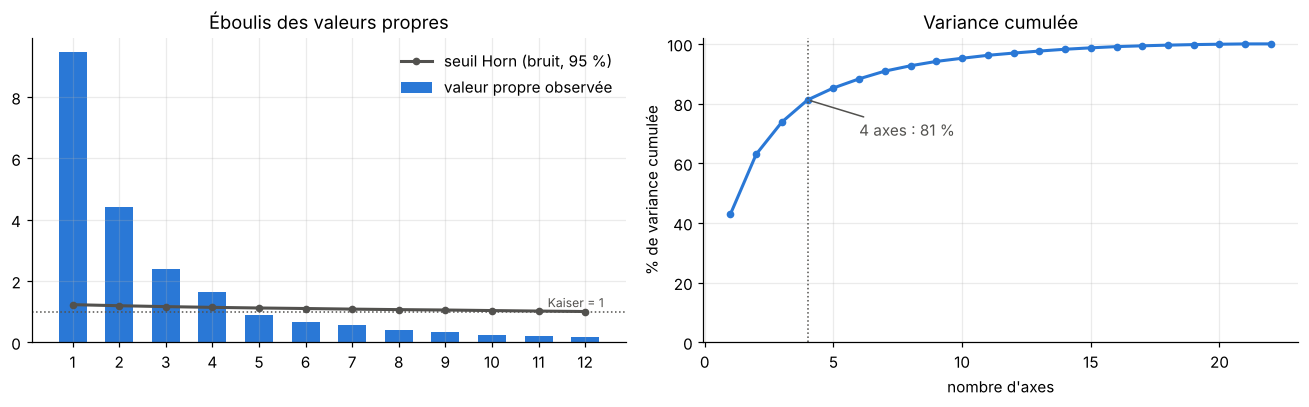

In [20]:
# ACP sur les variables standardisées, et choix du nombre d'axes (Kaiser + analyse parallèle de Horn)
acp = PCA().fit(Xz)
vp = acp.explained_variance_

rng = np.random.default_rng(0)
vp_hasard = np.array([PCA().fit(StandardScaler().fit_transform(rng.standard_normal(Xz.shape))).explained_variance_
                      for _ in range(50)])
seuil_horn = np.percentile(vp_hasard, 95, axis=0)
k_kaiser, k_horn = int((vp > 1).sum()), int((vp > seuil_horn).sum())
cum = acp.explained_variance_ratio_.cumsum()

print(pd.DataFrame({"valeur propre": vp[:8], "seuil Horn (95 %)": seuil_horn[:8],
                    "% variance": acp.explained_variance_ratio_[:8] * 100, "% cumulé": cum[:8] * 100},
                   index=[f"F{i+1}" for i in range(8)]).round(2).to_string())
print(f"\nAxes retenus : Kaiser = {k_kaiser}, Horn = {k_horn}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
x = np.arange(1, 13)
ax[0].bar(x, vp[:12], color="#2a78d6", width=0.6, label="valeur propre observée")
ax[0].plot(x, seuil_horn[:12], color="#52514e", lw=2, marker="o", ms=4, label="seuil Horn (bruit, 95 %)")
ax[0].axhline(1, color="#52514e", lw=1, ls=":")
ax[0].text(12.4, 1.05, "Kaiser = 1", ha="right", va="bottom", color="#52514e", fontsize=8)
ax[0].set_xticks(x); ax[0].set_title("Éboulis des valeurs propres"); ax[0].legend(frameon=False)
ax[1].plot(np.arange(1, len(cum) + 1), cum * 100, color="#2a78d6", lw=2, marker="o", ms=4)
ax[1].axvline(4, color="#52514e", lw=1, ls=":")
ax[1].annotate(f"4 axes : {cum[3]*100:.0f} %", (4, cum[3] * 100), xytext=(6, cum[3] * 100 - 12),
               arrowprops=dict(arrowstyle="-", color="#52514e"), color="#52514e")
ax[1].set_ylim(0, 102); ax[1].set_ylabel("% de variance cumulée"); ax[1].set_xlabel("nombre d'axes")
ax[1].set_title("Variance cumulée")
plt.tight_layout(); plt.show()

**Constat :** Kaiser et l'analyse parallèle de Horn s'accordent sur **4 axes**, qui résument 81 % de la variance (F1 43 %, F2 20 %, F3 11 %, F4 7 %). F5 (valeur propre 0,88) passe sous le seuil du bruit.

**Interprétation :** les 22 variables statiques décrivent en réalité 4 dimensions de la zone.

**Conséquence :** si on utilise l'ACP, on retient 4 axes pour l'interprétation, mais pas forcément pour la prédiction (voir plus bas).

Communalité sur 4 axes (part de la variance de la variable conservée), les 6 plus faibles :
part_logements_taux_impute    0.41
niveau_vie_median             0.43
taux_vacance_complete         0.68
anciennete_moyenne            0.70
part_2006_2019                0.70
taux_vacance                  0.73


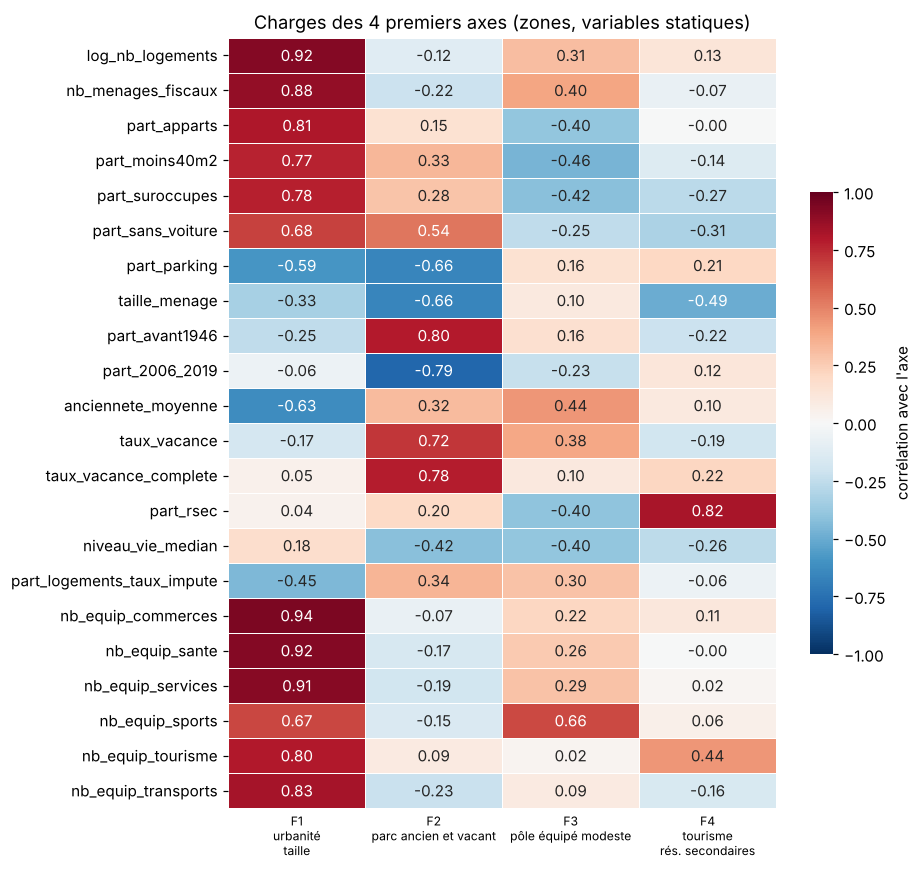

In [21]:
# Corrélations variables × axes (« charges ») et qualité de représentation (communalité) sur 4 axes
K = 4
# Orientation des axes pour la lecture : chaque axe est rendu positif sur une variable d'ancrage
ancres = ["log_nb_logements", "part_avant1946", "nb_equip_sports", "part_rsec"]
for k, a in enumerate(ancres):
    if acp.components_[k, STATIQUES.index(a)] < 0:
        acp.components_[k] *= -1

NOMS_AXES = {"F1": "F1 urbanité / taille", "F2": "F2 parc ancien et vacant", "F3": "F3 pôle équipé modeste", "F4": "F4 tourisme / rés. secondaires"}
charges = pd.DataFrame(acp.components_[:K].T * np.sqrt(vp[:K]), index=STATIQUES, columns=[f"F{i+1}" for i in range(K)])
communalite = (charges ** 2).sum(axis=1)

fig, ax = plt.subplots(figsize=(8.5, 8))
ax.grid(False)
sns.heatmap(charges, cmap="RdBu_r", vmin=-1, vmax=1, center=0, annot=True, fmt=".2f", linewidths=0.5,
            cbar_kws={"label": "corrélation avec l'axe", "shrink": 0.6}, ax=ax)
ax.set_xticklabels([NOMS_AXES[c].replace(" ", "\n", 1).replace(" / ", "\n") for c in charges.columns], rotation=0, fontsize=8)
ax.tick_params(axis="x", length=0)
ax.set_title("Charges des 4 premiers axes (zones, variables statiques)")
plt.tight_layout(); plt.show()

print("Communalité sur 4 axes (part de la variance de la variable conservée), les 6 plus faibles :")
print(communalite.sort_values().head(6).round(2).to_string())

**Constat :** lecture des axes, orientés pour être positifs sur leur variable d'ancrage :
- **F1 urbanité / taille** : nombre de logements, ménages, tous les équipements, part d'appartements et de petits logements, ménages sans voiture (≥ 0,7).
- **F2 parc ancien et vacant** : logements d'avant 1946 (0,80), vacance (0,72 à 0,78), contre logements récents 2006-2019 (−0,79), parkings et grands ménages. C'est un axe de déprise.
- **F3 pôle équipé modeste** : équipements sportifs, ancienneté, vacance, contre petits logements, résidences secondaires et niveau de vie élevé (−0,40).
- **F4 tourisme** : résidences secondaires (0,82), équipements touristiques, petits ménages.

Communalités faibles : `niveau_vie_median` n'est conservé qu'à 43 % sur 4 axes, et la qualité de donnée `part_logements_taux_impute` à 41 %.

**Interprétation :** les axes sont lisibles et cohérents avec l'économie du logement. Mais le **niveau de vie**, 4e meilleur prédicteur univarié (ρ = +0,62), est mal représenté.

**Conséquence :** si l'on modélise sur les axes, il faut garder `niveau_vie_median` à part, en plus des axes.

Corrélation de Spearman entre les axes et log(prix) moyen de la zone :
               F1    F2    F3    F4
appartement  0.44 -0.59 -0.48 -0.05
maison       0.47 -0.62 -0.53 -0.08


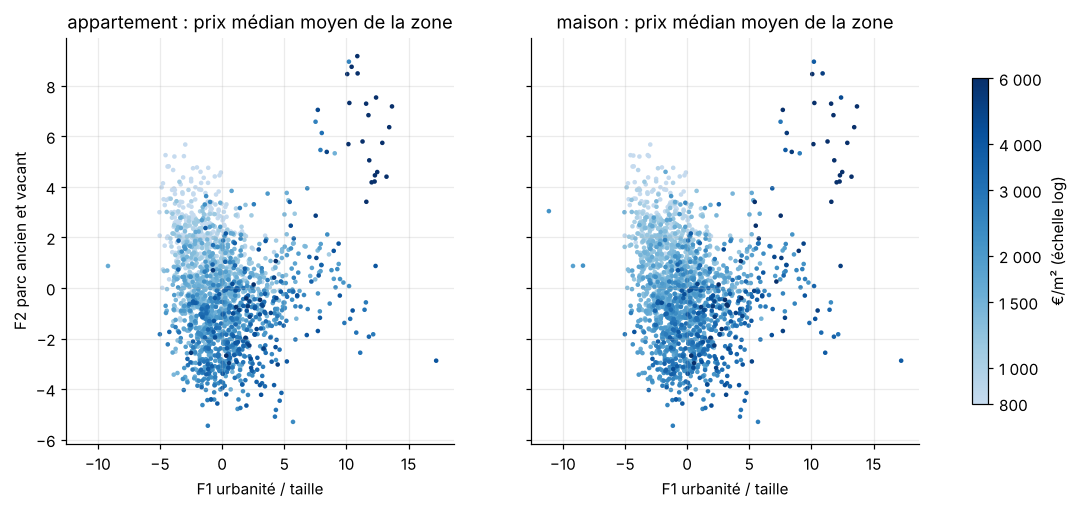

In [22]:
# Scores des zones sur les axes, et lien avec le niveau de prix moyen de la zone
scores = pd.DataFrame(acp.transform(Xz)[:, :K], index=zones.index, columns=[f"F{i+1}" for i in range(K)])

lp_zone = d.groupby(["sbv", "typebien"])["lp"].mean().unstack()
print("Corrélation de Spearman entre les axes et log(prix) moyen de la zone :")
print(pd.DataFrame({t: scores.corrwith(lp_zone[t], method="spearman") for t in lp_zone}).round(2).T.to_string())

bleus = plt.matplotlib.colors.LinearSegmentedColormap.from_list("bleus", plt.cm.Blues(np.linspace(0.25, 1, 256)))
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.8), sharex=True, sharey=True)
for a, t in zip(ax, ["appartement", "maison"]):
    s = scores.join(lp_zone[t].rename("lp")).dropna().sort_values("lp")
    sc = a.scatter(s["F1"], s["F2"], c=np.exp(s["lp"]), cmap=bleus, norm=plt.matplotlib.colors.LogNorm(800, 6000),
                   s=9, edgecolors="none")
    a.set_title(f"{t} : prix médian moyen de la zone"); a.set_xlabel(NOMS_AXES["F1"])
ax[0].set_ylabel(NOMS_AXES["F2"])
cb = fig.colorbar(sc, ax=ax, shrink=0.8, ticks=[800, 1000, 1500, 2000, 3000, 4000, 6000])
cb.ax.set_yticklabels(["800", "1 000", "1 500", "2 000", "3 000", "4 000", "6 000"]); cb.ax.minorticks_off()
cb.set_label("€/m² (échelle log)")
plt.show()

**Constat :** le prix moyen d'une zone est corrélé positivement à F1 (ρ ≈ +0,45) et négativement à F2 (≈ −0,60) et à F3 (≈ −0,50). F4 n'a pas de lien direct avec le niveau. Le nuage F1 × F2 montre un dégradé net : les zones chères sont urbaines ou à parc récent. Un groupe très urbain à parc ancien (en haut à droite, Paris) est le plus cher.

**Interprétation :** F2 (déprise) est le meilleur résumé du niveau de prix, devant l'urbanité. C'est cohérent avec `taux_vacance` en tête des corrélations (section B2).

**Conséquence :** les axes sont de bonnes **variables de contrôle** compactes pour les tests d'hypothèses.

In [23]:
# Bloc délinquance : 8 taux pour 1 000 habitants, qui varient dans le temps. Un seul axe suffit-il ?
CRIME = [c for c in df.columns if c.startswith("taux1_")]
cr = df[(df["typebien"] == "maison") & df[CRIME].notna().all(axis=1)][CRIME]
acp_crime = PCA().fit(StandardScaler().fit_transform(np.log1p(cr)))
print(f"{len(cr)} zones × années avec les 8 taux renseignés (2017+)")
print("% de variance par axe :", (acp_crime.explained_variance_ratio_[:4] * 100).round(1).tolist())
print("Charges F1 :", dict(zip([c.replace("taux1_", "") for c in CRIME],
                               (acp_crime.components_[0] * np.sqrt(acp_crime.explained_variance_[0])).round(2))))
print("\nCorrélations de Spearman entre taux (min / médiane) :",
      np.round(np.nanmin(cr.corr("spearman").where(~np.eye(8, dtype=bool))), 2), "/",
      np.round(np.nanmedian(cr.corr("spearman").where(~np.eye(8, dtype=bool))), 2))

16352 zones × années avec les 8 taux renseignés (2017+)
% de variance par axe : [47.1, 19.5, 12.0, 6.3]
Charges F1 : {'vols_vehicules': np.float64(0.83), 'vols_violents': np.float64(0.81), 'vols_sans_violence': np.float64(0.86), 'cambriolages': np.float64(0.45), 'destructions': np.float64(0.81), 'stupefiants': np.float64(0.7), 'violences_intrafamiliales': np.float64(0.41), 'violences_sexuelles': np.float64(0.42)}

Corrélations de Spearman entre taux (min / médiane) : 0.01 / 0.29


**Constat :** sur les 8 taux de délinquance, le premier axe ne capte que 47 % de la variance. Les vols (véhicules, avec et sans violence), les destructions et les stupéfiants chargent fort (0,7-0,86). Les cambriolages et les violences intrafamiliales ou sexuelles chargent peu (≈ 0,4). La corrélation médiane entre taux est de 0,29.

**Interprétation :** il n'y a pas un « niveau de délinquance » unique, mais au moins deux familles : la délinquance de voie publique, très urbaine, et les atteintes aux personnes ou cambriolages.

**Conséquence :** un score de délinquance unique (F1) suffit pour un contrôle, mais résumer tout le bloc en un indice perdrait la moitié de l'information. Pour un modèle à arbres, garder les 8 `taux1_*`.

In [24]:
# L'ACP fait-elle perdre de l'information prédictive ? Comparaison en validation croisée groupée par zone.
# Cible : niveau de prix RELATIF de la zone (log prix − médiane nationale de l'année et du type), moyenné sur les années.
nat = d.groupby(["typebien", "annee"])["lp"].median().rename("lp_nat")
d = d.join(nat, on=["typebien", "annee"])
d["rel"] = d["lp"] - d["lp_nat"]
cible_zone = d.groupby(["sbv", "typebien"])["rel"].mean().unstack()

def arbre():
    return HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, min_samples_leaf=20, random_state=0)

modeles = {
    "OLS, 22 variables":           lambda: make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge, 22 variables":         lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 13))),
    "OLS, 4 axes ACP":             lambda: make_pipeline(StandardScaler(), PCA(4), LinearRegression()),
    "OLS, 8 axes ACP":             lambda: make_pipeline(StandardScaler(), PCA(8), LinearRegression()),
    "Boosting, 22 variables":      arbre,
    "Boosting, 4 axes ACP":        lambda: make_pipeline(StandardScaler(), PCA(4), arbre()),
}
cv = KFold(5, shuffle=True, random_state=0)   # une ligne par zone : un KFold sur les zones est déjà un split groupé
res = []
for t in ["appartement", "maison"]:
    y = cible_zone[t].dropna(); Xm = zones.loc[y.index]
    for nom, f in modeles.items():
        pred = cross_val_predict(f(), Xm, y, cv=cv)
        res.append({"typebien": t, "modèle": nom,
                    "R²": 1 - ((y - pred) ** 2).sum() / ((y - y.mean()) ** 2).sum(),
                    "erreur médiane %": np.median(np.abs(np.expm1(pred - y))) * 100})
cout_acp = pd.DataFrame(res).pivot(index="modèle", columns="typebien").round(3)
print(cout_acp.loc[list(modeles)].to_string())

                                R²        erreur médiane %        
typebien               appartement maison      appartement  maison
modèle                                                            
OLS, 22 variables            0.794  0.912           13.634   7.576
Ridge, 22 variables          0.794  0.912           13.760   7.549
OLS, 4 axes ACP              0.711  0.821           17.956  12.628
OLS, 8 axes ACP              0.779  0.879           14.220   9.210
Boosting, 22 variables       0.782  0.911           13.705   7.654
Boosting, 4 axes ACP         0.697  0.825           17.681  12.253


**Constat :** pour estimer le niveau relatif d'une zone à partir de ses seules caractéristiques (validation croisée par zone) :
- les 22 variables brutes donnent R² = 0,79 (appartements) et 0,91 (maisons), avec 13,6 % et 7,6 % d'erreur médiane ;
- **4 axes ACP dégradent nettement** le résultat : R² 0,71 et 0,82, erreur 18,0 % et 12,6 % ;
- 8 axes se rapprochent sans égaler les variables brutes ;
- Ridge = OLS, et le boosting n'apporte rien sur les variables brutes.

**Interprétation :** les 19 % de variance « perdus » par l'ACP contiennent du signal prix, notamment le niveau de vie et le tourisme. La colinéarité ne nuit pas à la **prédiction** (Ridge n'améliore pas OLS), seulement à l'interprétation des coefficients.

**Conséquence — réponse à la question ACP :**
- **Pas d'ACP pour prédire.** Elle n'est pas nécessaire (83 obs. par variable, modèles tolérants à la colinéarité) et elle coûte de la précision.
- **ACP utile en complément** pour : (1) comprendre et nommer les dimensions des zones, (2) fournir des variables de contrôle compactes dans les tests d'hypothèses, (3) une régression linéaire dont on veut lire les coefficients, avec 4 axes + `niveau_vie_median`.
- Pour réduire la colinéarité sans ACP : retirer `nb_menages_fiscaux` (doublon de `log_nb_logements`) et ramener les équipements au nombre de logements.
- Si l'ACP entre dans un modèle, l'ajuster dans un `Pipeline` sur les seules zones d'entraînement.

# F. Synthèse : réduction de dimension

**Contributeurs :** Gabrielle · **Date :** 03/11/2026

**Non pour prédire, oui pour comprendre.**
- **Pour prédire :** avec 83 zones par variable, il n'y a pas de problème de dimension, et la colinéarité ne nuit pas à la prédiction (Ridge = OLS). Une ACP à 4 axes **dégrade** l'estimation du niveau des zones (R² 0,91 → 0,82 pour les maisons).
- **Pour comprendre :** Bartlett et KMO = 0,86 valident l'ACP. Kaiser et Horn retiennent 4 axes (81 %) : urbanité, parc ancien et vacant, pôle équipé modeste, tourisme. Ces axes servent de variables de contrôle compactes dans les tests d'hypothèses et d'indicateurs lisibles.
- Pour une régression linéaire interprétable : 4 axes + `niveau_vie_median` (mal représenté par les axes).
- Le bloc délinquance ne se résume pas à un seul axe (47 %).
- Si l'ACP entre dans un modèle, l'ajuster dans un `Pipeline` sur les seules zones d'entraînement.

Objets disponibles pour la suite : `zones` (table zone, 22 variables statiques), `scores` (F1-F4 par zone), `NOMS_AXES`, `d` (lignes avec prix, colonnes `lp`, `lp_nat`, `rel`), `cible_zone` (niveau relatif moyen par zone × type), `CRIME`, `COUL`.